<a href="https://colab.research.google.com/github/bomfire-K/Data-Analysis-with-Open-Source/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_4%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# 오픈소스 기반 데이터 분석 4강 - 데이터 수집


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 4-1 CSV 파일 읽기

In [5]:
import pandas as pd

## data.csv 파일 읽기
df = pd.read_csv('data.csv', encoding='utf-8', sep = ',', header = 0, index_col=None, nrows=None)
print(df)

           날짜    체중  골격근량  체지방량
0  2025.02.06  64.7  30.0  11.1
1  2025.02.04  64.0  29.3  11.6


## 4-2 JSON 파일 읽기



In [ ]:
import json
import pandas as pd

## data.json 파일 출력

## data.json 파일 DataFrame 읽기

print(df)

## 4-3 텍스트 파일 읽기 및 데이터 추출

In [ ]:
import re

## 파일(callcenter20250301.log) 오픈 및 읽기
with open('callcenter20250301.log', 'r', encoding='utf-8') as f:
    content = f.read()
## 주민등록번호 패턴 생성

## 주민등록번호 마스킹


## 마스킹된 파일(callcenter20250301_masked.log) 오픈 및 쓰기


print("주민등록번호 마스킹 완료. 'callcenter20250301_masked.log.txt' 파일로 저장되었습니다.")

## 4-4 Open-Meteo의 무료 날씨 API를 통한 특정 지역 온도 조회

In [6]:
import requests
import json

url = "https://api.open-meteo.com/v1/forecast?=&=&current=temperature_2m"
params = {
    "latitude": "37.58638333",
    "longitude": "127.0203333",
    "current": "temperature_2m"
}

try:
    ## URL 및 파라미터 전송
    response=requests.get(url, params=params)
    response.raise_for_status()

    ## JSON 데이터 읽기
    data = response.json()

    print("API 응답:", data)
    print("서울시 종로구의 현재 온도는 : {0}{1} 입니다.".format(data['current']['temperature_2m'], data['current_units']['temperature_2m']))

except requests.exceptions.RequestException as e:
    print(f"API 호출 실패: {e}")
except json.JSONDecodeError as e:
    print(f"JSON 파싱 실패: {e}")

API 응답: {'latitude': 37.6, 'longitude': 127.0, 'generationtime_ms': 0.0400543212890625, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 29.0, 'current_units': {'time': 'iso8601', 'interval': 'seconds', 'temperature_2m': '°C'}, 'current': {'time': '2026-10-10T12:15', 'interval': 900, 'temperature_2m': 18.6}}
서울시 종로구의 현재 온도는 : 18.6°C 입니다.


## 4-5 Selenium과 lxml을 이용한 웹 스크래핑

In [ ]:
!curl -o google-chrome-stable_current_amd64.deb https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb
!apt install ./google-chrome-stable_current_amd64.deb -y
!pip install selenium webdriver_manager

In [ ]:
from selenium import webdriver
from selenium.webdriver.chrome.service import Service as ChromeService
from webdriver_manager.chrome import ChromeDriverManager
from selenium.webdriver.common.by import By
from lxml import html
import time

chrome_options = webdriver.ChromeOptions()
chrome_options.add_argument('--headless')               # 브라우저 창 없이 실행
chrome_options.add_argument('--no-sandbox')             # 보안모드 비활성화 (Colab 필수)
chrome_options.add_argument('--disable-dev-shm-usage')  # 메모리 부족 방지 (Colab 필수)
chrome_options.add_argument('--window-size=1920x1080')  # 창 크기 설정(가상)
chrome_options.add_argument('--disable-gpu')            # GPU 가속 비활성화 (일부 환경 안정성)
chrome_options.binary_location = "/usr/bin/google-chrome-stable"  # Colab용 크롬 경로 지정

## 드라이버 실행
driver = webdriver.Chrome(options=chrome_options)

## 사이트 접속


## 사이트 접속 대기


## 페이지 제목 출력


## 드라이버 종료
driver.quit()


# 실습 시나리오

## 공공데이터 포털 가입 및 데이터 신청

- [https://www.data.go.kr](https://www.data.go.kr)
- 한국환경공단 에어코리아 대기오염정보 데이터 신청

In [ ]:
import requests

## 데이터 수집 url 및 api key 설정


params = {
    'serviceKey': api_key,
    'returnType': 'json',
    'numOfRows': '100',
    'pageNo': '1',
    'sidoName': '서울',
    'ver': '1.0'
}

## 데이터 수집

## 호출 성공/실패 출력



In [7]:
import requests
import json

url = "https://apis.data.go.kr/B552845/perDay/price?serviceKey=gXRl05uDLbnKxqlgHEz88Da2HeulU1GNskbIyzJ21y1lK0COl%2F7g%2FRzAWu5izgXTZ6NNTBp6W4tInI8c39KuQQ%3D%3D&pageNo=1&numOfR&pageNo=1&numOfRows=200&returnType=JSON&cond[exmn_ymd::GTE]=20150101&cond[exmn_ymd::LTE]=20151231&cond[se_cd::EQ]=02&cond[ctgry_cd::EQ]=200&cond[item_cd::EQ]=211&cond[grd_cd::EQ]=04&cond[sgg_cd::EQ]=1101&cond[mrkt_cd::EQ]=0110211&cond[vrty_cd::EQ]=01"
try:
    ## URL 및 파라미터 전송
    response=requests.get(url, params=params)
    response.raise_for_status()

    ## JSON 데이터 읽기
    data = response.json()

    print("API 응답:", data)
    print("서울시 종로구의 현재 온도는 : {0}{1} 입니다.".format(data['current']['temperature_2m'], data['current_units']['temperature_2m']))

except requests.exceptions.RequestException as e:
    print(f"API 호출 실패: {e}")
except json.JSONDecodeError as e:
    print(f"JSON 파싱 실패: {e}")

API 응답: {'response': {'body': {'dataType': 'JSON', 'items': {'item': [{'ctgry_cd': '200', 'ctgry_nm': '채소류', 'exmn_dd_cnvs_prc': '9000', 'exmn_dd_prc': '9000', 'exmn_ymd': '20150512', 'grd_cd': '04', 'grd_nm': '상품', 'item_cd': '211', 'item_nm': '배추', 'mrkt_cd': '0110211', 'mrkt_nm': '가락도매', 'orgnl_reg_dt': '2015-05-12T13:53:35Z', 'se_cd': '02', 'se_nm': '중도매', 'sgg_cd': '1101', 'sgg_nm': '서울', 'unit': 'kg(그물망 3포기)', 'unit_sz': '10', 'vrty_cd': '01', 'vrty_nm': '봄'}, {'ctgry_cd': '200', 'ctgry_nm': '채소류', 'exmn_dd_cnvs_prc': '8000', 'exmn_dd_prc': '8000', 'exmn_ymd': '20150513', 'grd_cd': '04', 'grd_nm': '상품', 'item_cd': '211', 'item_nm': '배추', 'mrkt_cd': '0110211', 'mrkt_nm': '가락도매', 'orgnl_reg_dt': '2015-05-13T13:47:27Z', 'se_cd': '02', 'se_nm': '중도매', 'sgg_cd': '1101', 'sgg_nm': '서울', 'unit': 'kg(그물망 3포기)', 'unit_sz': '10', 'vrty_cd': '01', 'vrty_nm': '봄'}, {'ctgry_cd': '200', 'ctgry_nm': '채소류', 'exmn_dd_cnvs_prc': '8000', 'exmn_dd_prc': '8000', 'exmn_ymd': '20150514', 'grd_cd': '04'

KeyError: 'current'

In [45]:
import requests
import json

try:
    variety_codes = ["01", "02", "03", "06"]
    all_items = []

    for variety_code in variety_codes:
        page = 1
        collected_count = 0
        while True:
            url = f"https://apis.data.go.kr/B552845/perDay/price?serviceKey=gXRl05uDLbnKxqlgHEz88Da2HeulU1GNskbIyzJ21y1lK0COl%2F7g%2FRzAWu5izgXTZ6NNTBp6W4tInI8c39KuQQ%3D%3D&pageNo={page}&numOfRows=1000&returnType=JSON&cond[exmn_ymd::GTE]=20150101&cond[exmn_ymd::LTE]=20241231&cond[se_cd::EQ]=02&cond[ctgry_cd::EQ]=200&cond[item_cd::EQ]=211&cond[grd_cd::EQ]=04&cond[sgg_cd::EQ]=1101&cond[mrkt_cd::EQ]=0110211&cond[vrty_cd::EQ]={variety_code}"

            ## URL 및 파라미터 전송
            response=requests.get(url)
            response.raise_for_status()
            ## JSON 데이터 읽기
            data = response.json()
            body = data["response"]["body"]
            total_count = int(body["totalCount"])
            items = body["items"]["item"]

            all_items.extend(items)
            collected_count += len(items)

            if collected_count >= total_count:
                break

            page += 1

    print("가져온 데이터 개수:", len(all_items))
    print("가져온 데이터:", all_items)


except requests.exceptions.RequestException as e:
    print(f"API 호출 실패: {e}")
except json.JSONDecodeError as e:
    print(f"JSON 파싱 실패: {e}")

가져온 데이터 개수: 2644
가져온 데이터: [{'ctgry_cd': '200', 'ctgry_nm': '채소류', 'exmn_dd_cnvs_prc': '9000', 'exmn_dd_prc': '9000', 'exmn_ymd': '20150512', 'grd_cd': '04', 'grd_nm': '상품', 'item_cd': '211', 'item_nm': '배추', 'mrkt_cd': '0110211', 'mrkt_nm': '가락도매', 'orgnl_reg_dt': '2015-05-12T13:53:35Z', 'se_cd': '02', 'se_nm': '중도매', 'sgg_cd': '1101', 'sgg_nm': '서울', 'unit': 'kg(그물망 3포기)', 'unit_sz': '10', 'vrty_cd': '01', 'vrty_nm': '봄'}, {'ctgry_cd': '200', 'ctgry_nm': '채소류', 'exmn_dd_cnvs_prc': '8000', 'exmn_dd_prc': '8000', 'exmn_ymd': '20150513', 'grd_cd': '04', 'grd_nm': '상품', 'item_cd': '211', 'item_nm': '배추', 'mrkt_cd': '0110211', 'mrkt_nm': '가락도매', 'orgnl_reg_dt': '2015-05-13T13:47:27Z', 'se_cd': '02', 'se_nm': '중도매', 'sgg_cd': '1101', 'sgg_nm': '서울', 'unit': 'kg(그물망 3포기)', 'unit_sz': '10', 'vrty_cd': '01', 'vrty_nm': '봄'}, {'ctgry_cd': '200', 'ctgry_nm': '채소류', 'exmn_dd_cnvs_prc': '8000', 'exmn_dd_prc': '8000', 'exmn_ymd': '20150514', 'grd_cd': '04', 'grd_nm': '상품', 'item_cd': '211', 'item_n

In [50]:
import pandas as pd

df = pd.DataFrame(all_items)
display(df.head())

,ctgry_cd,ctgry_nm,exmn_dd_cnvs_prc,exmn_dd_prc,exmn_ymd,grd_cd,grd_nm,item_cd,item_nm,mrkt_cd,mrkt_nm,orgnl_reg_dt,se_cd,se_nm,sgg_cd,sgg_nm,unit,unit_sz,vrty_cd,vrty_nm
0,200,채소류,9000,9000,20150512,04,상품,211,배추,0110211,가락도매,2015-05-12T13:53:35Z,02,중도매,1101,서울,kg(그물망 3포기),10,01,봄
1,200,채소류,8000,8000,20150513,04,상품,211,배추,0110211,가락도매,2015-05-13T13:47:27Z,02,중도매,1101,서울,kg(그물망 3포기),10,01,봄
2,200,채소류,8000,8000,20150514,04,상품,211,배추,0110211,가락도매,2015-05-18T14:51:22Z,02,중도매,1101,서울,kg(그물망 3포기),10,01,봄
3,200,채소류,8000,8000,20150515,04,상품,211,배추,0110211,가락도매,2015-05-18T14:57:50Z,02,중도매,1101,서울,kg(그물망 3포기),10,01,봄
4,200,채소류,10000,10000,20150518,04,상품,211,배추,0110211,가락도매,2015-05-21T11:25:53Z,02,중도매,1101,서울,kg(그물망 3포기),10,01,봄


In [57]:
df["exmn_ymd"] = pd.to_datetime(df["exmn_ymd"], format="%Y%m%d")
df["year"] = df["exmn_ymd"].dt.year
def get_season(month):
    if month in [3, 4, 5]:
        return "봄"
    elif month in [6, 7, 8]:
        return "여름"
    elif month in [9, 10, 11]:
        return "가을"
    else:
        return "겨울"

df["season"] = df["exmn_ymd"].dt.month.apply(get_season)
display(df[["year", "season", "exmn_ymd", "vrty_nm", "exmn_dd_prc"]])

,year,season,exmn_ymd,vrty_nm,exmn_dd_prc
0,2015,봄,2015-05-12,봄,9000
1,2015,봄,2015-05-13,봄,8000
2,2015,봄,2015-05-14,봄,8000
3,2015,봄,2015-05-15,봄,8000
4,2015,봄,2015-05-18,봄,10000
...,...,...,...,...,...
2639,2024,겨울,2024-12-24,월동,12000
2640,2024,겨울,2024-12-26,월동,13200
2641,2024,겨울,2024-12-27,월동,12800
2642,2024,겨울,2024-12-30,월동,13000


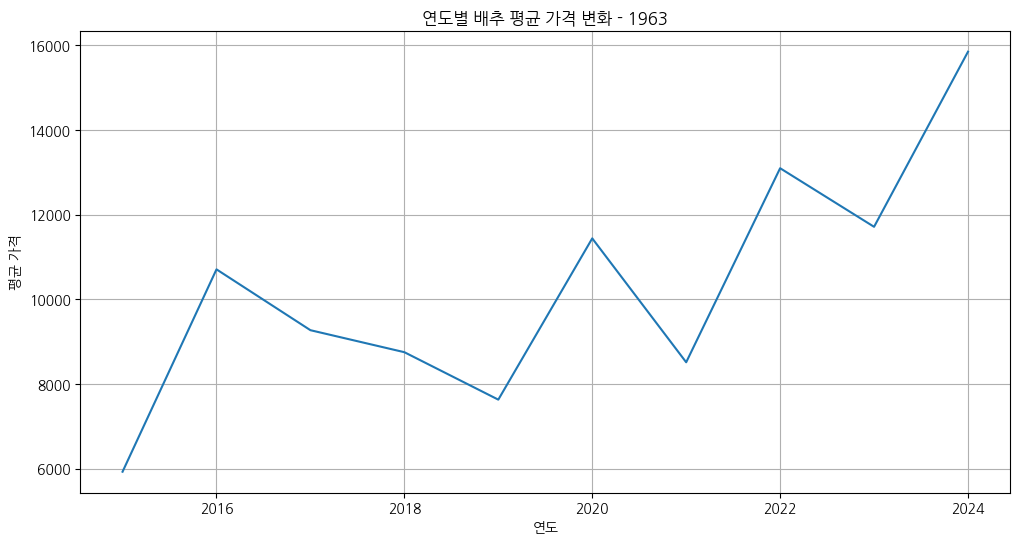

In [68]:
import koreanize_matplotlib
import matplotlib.pyplot as plt

df["exmn_dd_prc"] = pd.to_numeric(df["exmn_dd_prc"])
yearly_price = df.groupby("year")["exmn_dd_prc"].mean()

plt.figure(figsize=(12, 6))
plt.plot(yearly_price.index, yearly_price.values)
plt.title("연도별 배추 평균 가격 변화 - 1963")
plt.xlabel("연도")
plt.ylabel("평균 가격")
plt.grid(True)

plt.show()

In [66]:
!pip -q install koreanize-matplotlib
